##### import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
HousePricePrediction=pd.read_csv("HousePricePrediction.csv")
HousePricePrediction

<Axes: xlabel='LotArea', ylabel='TotalBsmtSF'>

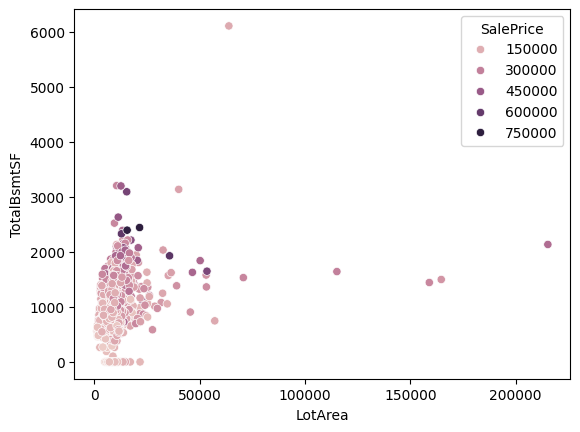

In [14]:
sns.scatterplot(x=HousePricePrediction["LotArea"], y=HousePricePrediction["TotalBsmtSF"], hue=HousePricePrediction["SalePrice"])

In [30]:
X = data.drop(columns=["Id", "SalePrice"])
y = data["SalePrice"]

In [31]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [32]:
X = X.fillna(X.median())
print("Missing values in X:", X.isnull().sum().sum())

Missing values in X: 0


In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_test.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
892,20,8414,8,1963,2003,0.0,1059.0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
1105,60,12256,5,1994,1995,0.0,1463.0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
413,30,8960,6,1927,1950,0.0,1008.0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
522,50,5000,7,1947,1950,0.0,1004.0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1036,20,12898,5,2007,2008,0.0,1620.0,0,0,1,...,0,0,0,0,0,0,0,1,0,0


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_test.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_FV,MSZoning_RH,MSZoning_RL,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
892,20,8414,8,1963,2003,0.0,1059.0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
1105,60,12256,5,1994,1995,0.0,1463.0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
413,30,8960,6,1927,1950,0.0,1008.0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
522,50,5000,7,1947,1950,0.0,1004.0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1036,20,12898,5,2007,2008,0.0,1620.0,0,0,1,...,0,0,0,0,0,0,0,1,0,0


In [34]:
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
y_pred = model.predict(X_test)
y_pred

array([168844.20187045, 243627.93266265, 114499.46802618, 157672.74928534,
       254809.72691561, 156499.88714209, 177912.63550292, 127514.41651571,
       133133.47244361, 149402.60951093, 130794.50236613, 123245.60221164,
        80364.27242007, 239205.09970653, 218458.40576163, 177909.93322611,
       217597.00518372, 179150.77327368, 135680.39694336, 232757.15292119,
       163631.47385302, 219363.09382648, 202562.61369718, 154850.31244007,
       223837.5082334 , 166839.82458248, 228156.71441652, 110537.3376599 ,
       215037.51335144, 205629.10183973, 115051.49676838, 231549.64641402,
       224622.45132015, 128364.14241411, 251497.64742701, 140828.28483851,
       170989.33623264, 217385.70991952, 255132.48015837,  77807.51078478,
       118583.69813312, 217906.68251222, 125596.27931999, 291090.36797416,
       141473.52251816, 105135.34718204, 128070.20017548, 130672.55127482,
       320648.92241053, 146484.93143582, 112112.92648899, 193792.29031155,
       123203.44465366, 2

In [36]:
y_test

892     154500.0
1105    325000.0
413     115000.0
522     159000.0
1036    315500.0
          ...   
479      89471.0
1361    260000.0
802     189000.0
651     108000.0
722     124500.0
Name: SalePrice, Length: 292, dtype: float64

In [37]:
#Evolution 
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("r-squared:", r2)

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - ((1-r2) * (n-1) / (n-p-1))
print("adjusted r^2:", adjusted_r2)

r-squared: 0.6195131796544862
adjusted r^2: 0.5708462607730833


In [38]:
X_test.shape

(292, 33)